# Supplementary Figure 4

Relationship between representations of competing scenes and memory-guided eye movements in other brain regions. Accompanies Figure 3. Reads `dataframes/pattern_sim_behav_data.csv` and `dataframes/pattern_sim_avg.csv`, produced by `figure3.ipynb` -- run that notebook first.

In [1]:
import os.path as op
import os
os.environ.setdefault("OUTDATED_IGNORE", "1")

import pandas as pd
import nibabel as nib
from scipy import stats
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
from nilearn.plotting import plot_stat_map

from mgvs_release import config
from mgvs_release.plotting import setup_style, plot_rank_bin_effect, save_fig
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
deriv_dir = config.DERIV_DIR
model = 'default'

save_dir = '../plots/'
dataframes_dir = '../dataframes/'

## Load previously computed dataframes

In [4]:
ps_diff_perf_sorted = pd.read_csv(op.join(dataframes_dir, 'pattern_sim_behav_data.csv'),
                                   index_col=0, float_precision='round_trip')
ps_diff_mean = pd.read_csv(op.join(dataframes_dir, 'pattern_sim_avg.csv'),
                            index_col=0, float_precision='round_trip')

## Supplementary Fig. 4A: Pattern similarity in anterior/posterior hippocampus

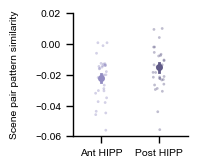

In [5]:
f, ax = plt.subplots(1, 1, figsize=(2, 1.7))
ant_post_pal = list(sns.color_palette('Purples_d', 2))
ax = sns.pointplot(x='roi', y='corr_z', order=['hipp_anterior', 'hipp_posterior'], errorbar='se',
                   hue='roi', hue_order=['hipp_anterior', 'hipp_posterior'], markersize=3.5, linewidth=2,
                   palette=ant_post_pal,
                   data=ps_diff_mean)
sns.stripplot(x='roi', y='corr_z', order=['hipp_anterior', 'hipp_posterior'],
              hue_order=['hipp_anterior', 'hipp_posterior'], alpha=.4, s=2,
              hue='roi', palette=ant_post_pal, zorder=-100,
              data=ps_diff_mean, ax=ax)
ax.set(xlabel='', xticks=range(2), xticklabels=['Ant HIPP', 'Post HIPP'], ylim=[-.06, .02],
       ylabel='Scene pair pattern similarity\n')
ax.legend_ = None
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'sfig4a'))

## Supplementary Fig. 4B: relationship between pattern similarity in anterior/posterior hippocampus and search error

Ant HIPP

In [6]:
ps_diff_perf_sorted_hpc_ant = ps_diff_perf_sorted.query("roi=='hipp_anterior' & sacc_type=='first'")
ps_diff_perf_sorted_hpc_ant = ps_diff_perf_sorted_hpc_ant.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

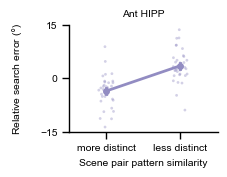

In [7]:
plot_rank_bin_effect(ps_diff_perf_sorted_hpc_ant, y='next_targ_err_center', color=ant_post_pal[0],
                      title='Ant HIPP', ylabel='Relative search error ($\degree$)\n',
                      ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'sfig4b_ant.svg'))

In [8]:
# Smaller saccade errors for more distinct (lower pattern similarity) pairs vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_hpc_ant.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_hpc_ant.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-4.3272,31,two-sided,0.000146,"[-10.44, -3.75]",0.429541,181.857,0.653258


Post HIPP

In [9]:
ps_diff_perf_sorted_hpc_post = ps_diff_perf_sorted.query("roi=='hipp_posterior' & sacc_type=='first'")
ps_diff_perf_sorted_hpc_post = ps_diff_perf_sorted_hpc_post.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

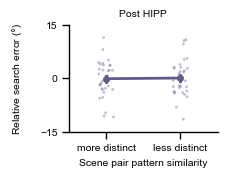

In [10]:
plot_rank_bin_effect(ps_diff_perf_sorted_hpc_post, y='next_targ_err_center', color=ant_post_pal[1],
                      title='Post HIPP', ylabel='Relative search error ($\degree$)\n',
                      ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'sfig4b_post.svg'))

In [11]:
# No difference in saccade errors for more distinct (lower pattern similarity) vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_hpc_post.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_hpc_post.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.107213,31,two-sided,0.915311,"[-3.84, 3.45]",0.011519,0.19,0.050457


In [12]:
# Interaction between anterior/posterior hippocampus and lower/higher pattern similarity on saccade errors
pg.rm_anova(data=ps_diff_perf_sorted.query("roi=='hipp_anterior' or roi=='hipp_posterior'"),
            dv='next_sacc_targ_err', subject='subj', effsize='np2', within=['roi', 'rank_bin'])

/home/sef2177/miniconda3/envs/MGVS-release-2022/lib/python3.8/site-packages/pingouin/parametric.py:764: RuntimeWarning: divide by zero encountered in double_scalars
  ef_a = (f_a * df_a) / (f_a * df_a + df_as)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,np2,eps
0,roi,6.462349e-27,1,31,6.462349e-27,-31.000000,1.000000,1.000000,-inf,1.0
1,rank_bin,3.514231e+02,1,31,3.514231e+02,8.917585,0.005476,0.005476,0.223400,1.0
2,roi * rank_bin,2.931263e+02,1,31,2.931263e+02,10.756866,0.002570,0.002570,0.257607,1.0


## Supplementary Fig. 4C: Scene pair pattern similarity for all ROIs

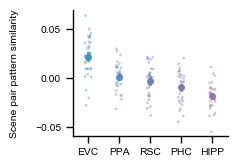

In [13]:
f, ax = plt.subplots(1, 1, figsize=(2.4, 1.7))
all_roi_pal = sns.blend_palette(['#4393c3', '#9970ab'], n_colors=5, input='hex')
ax = sns.pointplot(x='roi', y='corr_z', order=['V1_V3', 'CoS-places', 'rsc', 'phc', 'hipp'], errorbar='se',
                   hue='roi', hue_order=['V1_V3', 'CoS-places', 'rsc', 'phc', 'hipp'],
                   markersize=3.5, linewidth=2,
                   palette=all_roi_pal,
                   data=ps_diff_mean)
sns.stripplot(x='roi', y='corr_z', order=['V1_V3', 'CoS-places', 'rsc', 'phc', 'hipp'],
              hue_order=['V1_V3', 'CoS-places', 'rsc', 'phc', 'hipp'], alpha=.4, s=2,
              hue='roi', palette=all_roi_pal, zorder=-100,
              data=ps_diff_mean, ax=ax)
ax.set(xlabel='', xticks=range(5), xticklabels=['EVC', 'PPA', 'RSC', 'PHC', 'HIPP'],
       ylim=[-.06, .07], yticks=[-.05, 0, .05],
       ylabel='Scene pair pattern similarity\n')
ax.legend_ = None
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'sfig4c'))

## Supplementary Fig. 4D: relationship between pattern similarity in PPA, RSC, PHC and search error

PPA

In [14]:
ps_diff_perf_sorted_ppa = ps_diff_perf_sorted.query("roi=='CoS-places' & sacc_type=='first'")
ps_diff_perf_sorted_ppa = ps_diff_perf_sorted_ppa.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

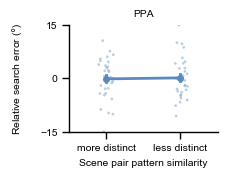

In [15]:
plot_rank_bin_effect(ps_diff_perf_sorted_ppa, y='next_targ_err_center', color=all_roi_pal[1], title='PPA',
                      ylabel='Relative search error ($\degree$)\n', ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'sfig4d_ppa.svg'))

In [16]:
# No difference in saccade errors for more distinct (lower pattern similarity) vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_ppa.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_ppa.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.139045,31,two-sided,0.890314,"[-4.36, 3.8]",0.016524,0.191,0.050941


RSC

In [17]:
ps_diff_perf_sorted_rsc = ps_diff_perf_sorted.query("roi=='rsc' & sacc_type=='first'")
ps_diff_perf_sorted_rsc = ps_diff_perf_sorted_rsc.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

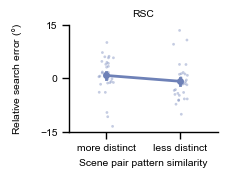

In [18]:
plot_rank_bin_effect(ps_diff_perf_sorted_rsc, y='next_targ_err_center', color=all_roi_pal[2], title='RSC',
                      ylabel='Relative search error ($\degree$)\n', ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'sfig4d_rsc.svg'))

In [19]:
# No difference in saccade errors for more distinct (lower pattern similarity) vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_rsc.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_rsc.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,0.903126,31,two-sided,0.373423,"[-2.05, 5.31]",0.097927,0.275,0.083634


PHC

In [20]:
ps_diff_perf_sorted_phc = ps_diff_perf_sorted.query("roi=='phc' & sacc_type=='first'")
ps_diff_perf_sorted_phc = ps_diff_perf_sorted_phc.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

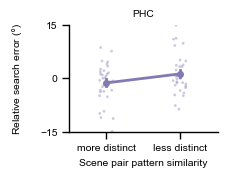

In [21]:
plot_rank_bin_effect(ps_diff_perf_sorted_phc, y='next_targ_err_center', color=all_roi_pal[3], title='PHC',
                      ylabel='Relative search error ($\degree$)\n', ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'sfig4d_phc.svg'))

In [22]:
# No difference in saccade errors for more distinct (lower pattern similarity) vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_phc.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_phc.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-1.315424,31,two-sided,0.198014,"[-6.51, 1.41]",0.152237,0.414,0.132844


In [23]:
# Interaction between all tested ROIs and lower/higher pattern similarity on saccade errors
all_rois_data = ps_diff_perf_sorted.query("sacc_type=='first'").query(
    "roi=='V1_V3' or roi=='rsc' or roi=='CoS-places' or roi=='phc' or roi=='hipp'")
pg.rm_anova(data=all_rois_data,
          dv='next_sacc_targ_err', subject='subj', effsize='np2', within=['roi', 'rank_bin'])

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,np2,eps
0,roi,0.000000,4,124,0.000000,-0.000000,1.000000,1.000000,-0.000000,-0.000000
1,rank_bin,219.493311,1,31,219.493311,2.751149,0.107270,0.107270,0.081513,1.000000
2,roi * rank_bin,429.403712,4,124,107.350928,2.573775,0.040955,0.054481,0.076660,0.801248


## Supplementary Fig. 4E: whole-brain searchlight

In [24]:
# Load precomputed searchlight outputs
behav_smooth = 'mni_smooth'

bg_img = nib.load(op.join(deriv_dir, 'searchlight-scene', 'mni',
                           'tpl-MNI152NLin2009cAsym_res-01_desc-brain_T1w.nii.gz'))

nii_path = op.join(deriv_dir, 'searchlight-scene', 'mni',
                    'behav_t_targ_err_' + behav_smooth + '_neg_tfce_p_tstat1.nii.gz')
stat_nii = nib.load(nii_path)

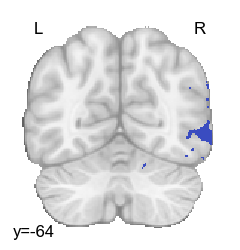

In [25]:
display = plot_stat_map(stat_nii, bg_img=bg_img, threshold=.99, display_mode='y', cut_coords=[-64],
                         black_bg=False, cmap='coolwarm_r', colorbar=False)
save_fig(display, op.join(save_dir, 'sfig4e_coronal_lo'))

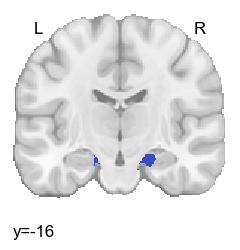

In [26]:
display = plot_stat_map(stat_nii, bg_img=bg_img, threshold=.99, display_mode='y', cut_coords=[-16],
                         black_bg=False, cmap='coolwarm_r', colorbar=False)
save_fig(display, op.join(save_dir, 'sfig4e_coronal_hipp'))

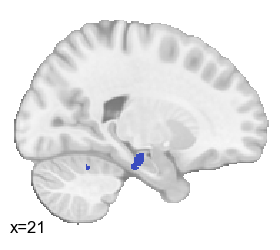

In [27]:
display = plot_stat_map(stat_nii, bg_img=bg_img, threshold=.99, display_mode='x', cut_coords=[21],
                         black_bg=False, cmap='coolwarm_r', colorbar=False)
save_fig(display, op.join(save_dir, 'sfig4e_sagittal_hipp'))